<a href="https://colab.research.google.com/github/eng-mohamedfathy/Land-Type-Classification/blob/main/Land_Type_Classification_Project_Advanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Land Type Classification Using Deep Learning and Satellite Imagery

This notebook builds a 10-class EuroSAT image classifier with a pretrained ResNet50. Run the cells in order in Google Colab. The training cell is intentionally separate so you can start training when you are ready.

**Workflow:** data audit and preparation → transfer learning → validation → final test evaluation → saved model and image inference.


## 1. Project Overview

EuroSAT contains 27,000 RGB satellite images across 10 land-cover classes. The target split is 70% training, 15% validation, and 15% testing. ResNet50 expects 224 × 224 inputs, so the original 64 × 64 images will be resized.

In [1]:
PROJECT_NAME = "Land Type Classification Using Deep Learning and Satellite Imagery"
DATASET_NAME = "EuroSAT"
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42

print(PROJECT_NAME)
print(f"Dataset: {DATASET_NAME} | Classes: {NUM_CLASSES} | Input: {IMAGE_SIZE}x{IMAGE_SIZE} RGB")
print(f"Split: 70% train / 15% validation / 15% test | Batch size: {BATCH_SIZE}")

Land Type Classification Using Deep Learning and Satellite Imagery
Dataset: EuroSAT | Classes: 10 | Input: 224x224 RGB
Split: 70% train / 15% validation / 15% test | Batch size: 32


## 2. Environment Setup

Import the project dependencies, set reproducibility controls, and select the available GPU when Colab provides one. Colab already includes the required packages in its standard PyTorch runtime.

In [2]:
import copy
import random
import sys
import time
from pathlib import Path
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms
from torchvision.datasets import EuroSAT

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("/content/eurosat_data") if Path("/content").exists() else Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available; training will use CPU and take longer.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


## 3. Dataset Collection

Load EuroSAT through torchvision. The download is performed only if the dataset is not already present in the selected data directory.

In [3]:
dataset = EuroSAT(root=str(DATA_DIR), download=True)
class_names = dataset.classes
targets = np.asarray(dataset.targets, dtype=np.int64)

print("Dataset downloaded and loaded.")
print("Total images:", len(dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

100%|██████████| 94.3M/94.3M [00:01<00:00, 93.1MB/s]


Dataset downloaded and loaded.
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 4. Exploratory Data Analysis (EDA)

Check the number of images in each class and visualize the distribution. EuroSAT is close to balanced, with modest differences in a few class counts.

                  Class  Number of Images
0            AnnualCrop              3000
1                Forest              3000
2  HerbaceousVegetation              3000
3               Highway              2500
4            Industrial              2500
5               Pasture              2000
6         PermanentCrop              2500
7           Residential              3000
8                 River              2500
9               SeaLake              3000


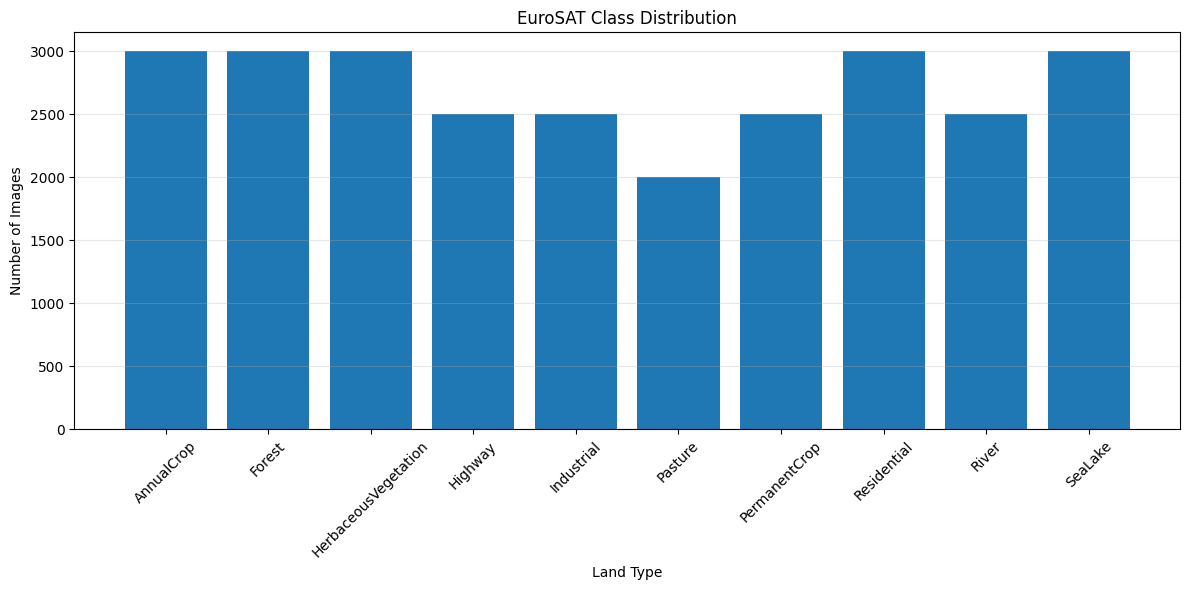

In [4]:
class_counts = pd.Series(dataset.targets).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": dataset.classes,
    "Number of Images": class_counts.values
})

print(class_distribution)

plt.figure(figsize=(12, 6))
plt.bar(
    class_distribution["Class"],
    class_distribution["Number of Images"]
)
plt.title("EuroSAT Class Distribution")
plt.xlabel("Land Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Image Understanding

Display one representative image from each class. The examples remain in their original 64 × 64 RGB form at this stage.

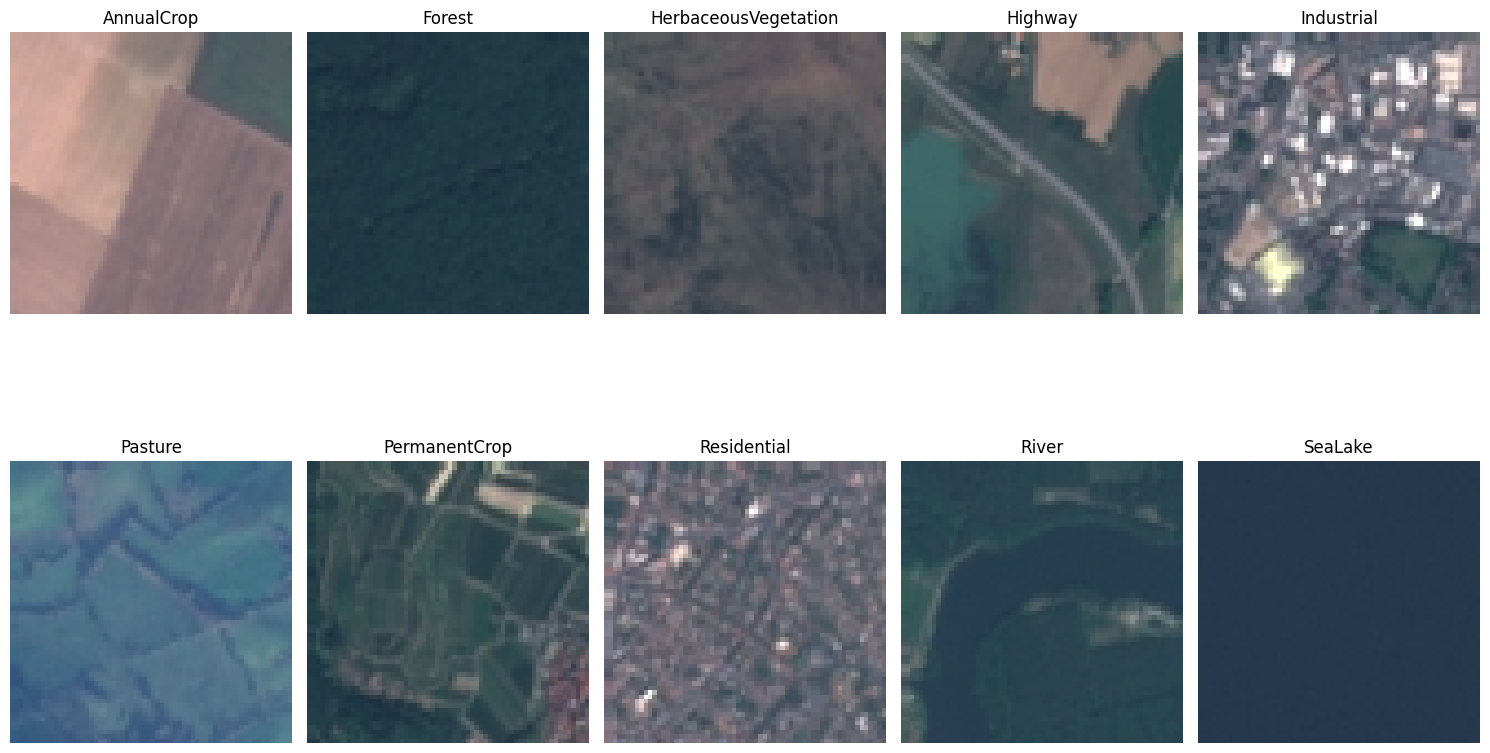

In [5]:
class_images = defaultdict(list)
for index, label in enumerate(targets):
    class_images[int(label)].append(index)

plt.figure(figsize=(15, 10))
for class_id, class_name in enumerate(class_names):
    image_index = random.choice(class_images[class_id])
    image, _ = dataset[image_index]
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Inspect a raw sample before defining model transforms. EuroSAT images are RGB PIL images with 8-bit pixel values; resizing and normalization are applied in the transformation stage.

In [6]:
sample_image, sample_label = dataset[0]
image_array = np.asarray(sample_image)

print("Image class:", class_names[sample_label])
print("Image mode:", sample_image.mode)
print("Image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Pixel range:", int(image_array.min()), "to", int(image_array.max()))

assert sample_image.mode == "RGB", "Expected an RGB image."
assert image_array.shape == (64, 64, 3), "Expected a 64x64 RGB EuroSAT image."

Image class: AnnualCrop
Image mode: RGB
Image shape: (64, 64, 3)
Image data type: uint8
Pixel range: 82 to 204


## 7. Dataset Splitting

Create reproducible stratified splits so each subset keeps approximately the same class distribution. The test set is held out until the final evaluation.

In [7]:
all_indices = np.arange(len(targets))

test_count = int(round(0.15 * len(all_indices)))
val_count = int(round(0.15 * len(all_indices)))

train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=test_count,
    random_state=SEED,
    stratify=targets,
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_count,
    random_state=SEED,
    stratify=targets[train_val_indices],
)

split_summary = pd.DataFrame({
    "Class": class_names,
    "Train": np.bincount(targets[train_indices], minlength=NUM_CLASSES),
    "Validation": np.bincount(targets[val_indices], minlength=NUM_CLASSES),
    "Test": np.bincount(targets[test_indices], minlength=NUM_CLASSES),
})

print(f"Training images:   {len(train_indices):,}")
print(f"Validation images: {len(val_indices):,}")
print(f"Testing images:    {len(test_indices):,}")
display(split_summary)

assert (len(train_indices), len(val_indices), len(test_indices)) == (18_900, 4_050, 4_050)

Training images:   18,900
Validation images: 4,050
Testing images:    4,050


,Class,Train,Validation,Test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


## 8. Image Transformations

Resize each image to 224 × 224 and apply ImageNet normalization expected by pretrained ResNet50 weights. Random flips and rotation are used only for training; validation and test transforms are deterministic.

In [8]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training and evaluation transforms are ready.")

Training and evaluation transforms are ready.


## 9. Dataset Preparation

Create separate dataset views so random augmentation is applied to training examples only. Each view uses the same underlying EuroSAT file ordering as the stratified indices.

In [9]:
train_data = EuroSAT(root=str(DATA_DIR), download=False, transform=train_transform)
eval_data = EuroSAT(root=str(DATA_DIR), download=False, transform=eval_transform)

train_set = Subset(train_data, train_indices.tolist())
val_set = Subset(eval_data, val_indices.tolist())
test_set = Subset(eval_data, test_indices.tolist())

assert train_data.classes == class_names
assert eval_data.classes == class_names
print("Prepared dataset sizes:", len(train_set), len(val_set), len(test_set))

Prepared dataset sizes: 18900 4050 4050


## 10. DataLoader Creation

Load batches of 32 images. Pinned memory is enabled on GPU systems, while a small worker count keeps Colab memory use manageable.

In [10]:
NUM_WORKERS = 2 if device.type == "cuda" else 0
loader_settings = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
}

train_loader = DataLoader(train_set, shuffle=True, **loader_settings)
val_loader = DataLoader(val_set, shuffle=False, **loader_settings)
test_loader = DataLoader(test_set, shuffle=False, **loader_settings)

images_batch, labels_batch = next(iter(train_loader))
print("Image batch shape:", tuple(images_batch.shape))
print("Label batch shape:", tuple(labels_batch.shape))
print("Batch size:", BATCH_SIZE)
del images_batch, labels_batch

Image batch shape: (32, 3, 224, 224)
Label batch shape: (32,)
Batch size: 32


## 11. Model Building (ResNet50)

Initialize ResNet50 with ImageNet pretrained weights and replace its final fully connected layer with a 10-class classifier. The first run may download the pretrained weights.

In [11]:
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

print("Architecture: ResNet50")
print("Output classes:", model.fc.out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 236MB/s]

Architecture: ResNet50
Output classes: 10
Device: cuda


## 12. Transfer Learning Configuration

Freeze the earlier feature extractor and fine-tune the final ResNet block (`layer4`) together with the new classifier. This reduces trainable parameters and GPU memory use while adapting high-level features to EuroSAT.

In [12]:
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,}")

Trainable parameters: 14,985,226 / 23,528,522


## 13. Loss Function and Optimizer

Use multiclass cross-entropy and Adam. Only parameters enabled for fine-tuning are passed to the optimizer.

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    (parameter for parameter in model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")

Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 14. Model Training

Define reusable epoch functions. Training loss and accuracy are averaged over examples, and the frozen backbone's BatchNorm layers keep their pretrained running statistics.

In [14]:
def run_epoch(loader, training=False):
    model.train(training)
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_count

    return total_loss / total, correct / total

print("Training and validation epoch functions are ready.")

Training and validation epoch functions are ready.


## 15. Validation and Performance Monitoring

This is the training cell. It runs one training and one validation pass per epoch, tracks loss and accuracy, and retains the weights with the lowest validation loss. Execute it manually when ready; no training is started by the setup cells.

Epoch 01/15 | train loss 0.3261, accuracy 0.9110 | val loss 0.0953, accuracy 0.9706 | 11.4s
Epoch 02/15 | train loss 0.0979, accuracy 0.9679 | val loss 0.0752, accuracy 0.9758 | 9.7s
Epoch 03/15 | train loss 0.0677, accuracy 0.9764 | val loss 0.0781, accuracy 0.9728 | 10.3s
Epoch 04/15 | train loss 0.0510, accuracy 0.9827 | val loss 0.0647, accuracy 0.9793 | 9.8s
Epoch 05/15 | train loss 0.0446, accuracy 0.9854 | val loss 0.0571, accuracy 0.9822 | 10.0s
Epoch 06/15 | train loss 0.0321, accuracy 0.9898 | val loss 0.0559, accuracy 0.9849 | 10.3s
Epoch 07/15 | train loss 0.0284, accuracy 0.9905 | val loss 0.0561, accuracy 0.9847 | 10.4s
Epoch 08/15 | train loss 0.0271, accuracy 0.9907 | val loss 0.0692, accuracy 0.9810 | 10.4s
Epoch 09/15 | train loss 0.0216, accuracy 0.9932 | val loss 0.0675, accuracy 0.9817 | 9.8s
Epoch 10/15 | train loss 0.0163, accuracy 0.9950 | val loss 0.0651, accuracy 0.9825 | 10.2s
Early stopping: validation loss did not improve for 4 epochs.
Best epoch: 6 | best 

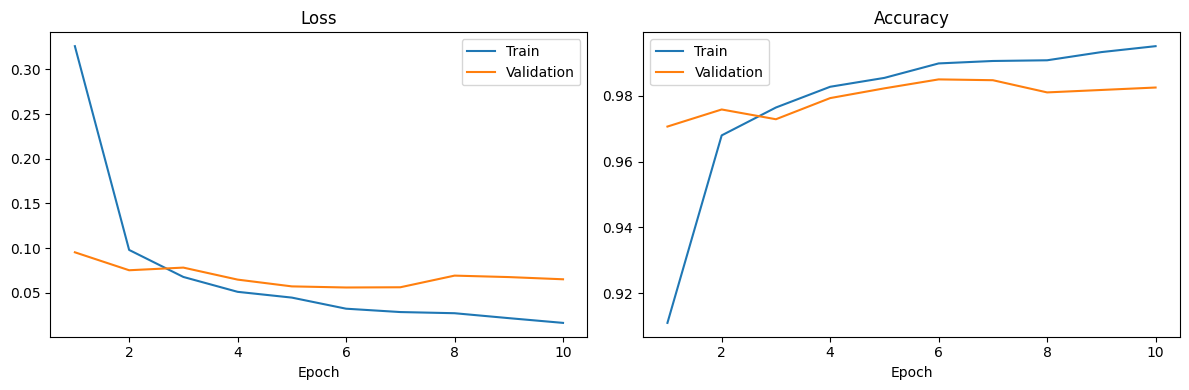

In [15]:
NUM_EPOCHS = 15
PATIENCE = 4
best_val_loss = float("inf")
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - epoch_start
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{elapsed:.1f}s"
    )
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

if best_model_state is None:
    raise RuntimeError("Training did not produce a best model checkpoint.")
model.load_state_dict(best_model_state)
print(f"Best epoch: {best_epoch} | best validation loss: {best_val_loss:.4f}")

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 16. Model Evaluation

Restore the best validation checkpoint and evaluate the held-out test set once. Do not use these test results to tune the model.

In [16]:
if best_model_state is None:
    raise RuntimeError("Run the training cell before evaluating the model.")
model.load_state_dict(best_model_state)
model.eval()

all_labels = []
all_predictions = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test accuracy: {test_accuracy:.4f}")

Test accuracy: 0.9820


## 17. Confusion Matrix

Show how often each true class is predicted as each class. Rows are true labels and columns are predicted labels.

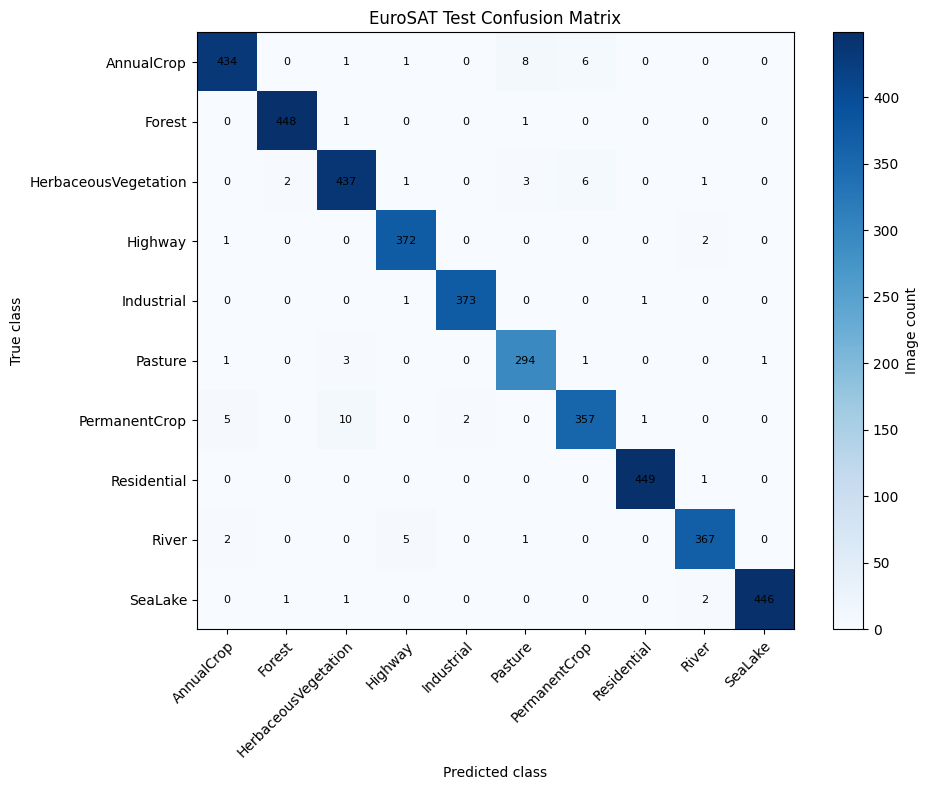

In [17]:
confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EuroSAT Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 18. Classification Report

Report per-class precision, recall, and F1-score, together with macro and weighted averages.

In [18]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
)
print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.9797    0.9644    0.9720       450
              Forest     0.9933    0.9956    0.9945       450
HerbaceousVegetation     0.9647    0.9711    0.9679       450
             Highway     0.9789    0.9920    0.9854       375
          Industrial     0.9947    0.9947    0.9947       375
             Pasture     0.9577    0.9800    0.9687       300
       PermanentCrop     0.9649    0.9520    0.9584       375
         Residential     0.9956    0.9978    0.9967       450
               River     0.9839    0.9787    0.9813       375
             SeaLake     0.9978    0.9911    0.9944       450

            accuracy                         0.9820      4050
           macro avg     0.9811    0.9817    0.9814      4050
        weighted avg     0.9820    0.9820    0.9820      4050



## 19. Model Saving

Save the best model weights and the class/preprocessing metadata needed to reproduce predictions. In Colab, download this file or save it to mounted Google Drive if you need it after the runtime ends.

In [19]:
MODEL_PATH = Path("best_resnet50_eurosat.pth")
checkpoint = {
    "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
}
torch.save(checkpoint, MODEL_PATH)
print("Saved model to:", MODEL_PATH.resolve())

Saved model to: /content/best_resnet50_eurosat.pth


## 20. Model Loading and Inference

Rebuild the model architecture without downloading weights, load the saved checkpoint, and define a prediction function that applies the same evaluation preprocessing.

In [20]:
loaded_checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=True)
loaded_class_names = loaded_checkpoint["class_names"]
loaded_model = models.resnet50(weights=None)
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, len(loaded_class_names))
loaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
loaded_model = loaded_model.to(device).eval()

inference_transform = transforms.Compose([
    transforms.Resize((loaded_checkpoint["image_size"], loaded_checkpoint["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=loaded_checkpoint["imagenet_mean"],
        std=loaded_checkpoint["imagenet_std"],
    ),
])

def classify_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = inference_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(loaded_model(image_tensor), dim=1)[0]
    predicted_index = int(probabilities.argmax().item())
    return loaded_class_names[predicted_index], float(probabilities[predicted_index].item())

print("Loaded model ready for single-image inference.")

Loaded model ready for single-image inference.


## 21. Testing with New Satellite Images

Upload one or more RGB satellite images in Google Colab. The model returns its most likely land-cover class and the associated softmax score.

In [21]:
from google.colab import files

uploaded_files = files.upload()
for filename in uploaded_files:
    predicted_class, confidence = classify_image(filename)
    print(f"{filename}: {predicted_class} (score: {confidence:.3f})")

Saving images-2.jpg to images-2.jpg
images-2.jpg: River (score: 0.818)


## 22. Final Conclusion

After running the notebook in order, you will have a reproducible EuroSAT training pipeline, a validation-selected ResNet50 checkpoint, final held-out test metrics, and a function for classifying new satellite images. Record the observed metrics in your project report after the final evaluation.

In [22]:
if "test_accuracy" in globals():
    print(f"Final held-out test accuracy: {test_accuracy:.4f}")
    print("See the classification report and confusion matrix above for detailed results.")
else:
    print("Run the training and evaluation cells to generate final test results.")
print("Inference function: classify_image(image_path)")

Final held-out test accuracy: 0.9820
See the classification report and confusion matrix above for detailed results.
Inference function: classify_image(image_path)


# Phase 2 — Model Comparison and Project Extensions

The completed ResNet50 work above is preserved as the project baseline. The sections below add an EfficientNet-B0 experiment, deeper error analysis, Grad-CAM, a clearly separate multispectral roadmap, optimization notes, and an optional Gradio interface. Run these cells one at a time after the relevant earlier cells. **No new model training starts until the dedicated training cell is run.**

The saved ResNet50 outputs report 98.20% test accuracy on 4,050 held-out images. EfficientNet-B0 metrics are intentionally left unreported until its training and test-evaluation cells have actually run.


## 23. Baseline Audit and Comparison Setup

Summarize the real ResNet50 test predictions already produced above. Its per-epoch times were printed to one decimal place; their sum is an estimate, not an exact timer measurement. The checkpoint size is read from the saved file when it is available.

In [23]:
baseline_report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

# Recorded epoch durations from the existing ResNet50 run (rounded to 0.1 s).
baseline_epoch_seconds = [12.3, 8.8, 10.5, 9.4, 10.4, 10.1, 10.2, 10.6, 10.6, 10.4]
baseline_training_seconds_approx = sum(baseline_epoch_seconds)
baseline_checkpoint_path = Path(MODEL_PATH)
baseline_checkpoint_mb = (
    baseline_checkpoint_path.stat().st_size / (1024 ** 2)
    if baseline_checkpoint_path.exists()
    else np.nan
)

baseline_audit = pd.DataFrame([{
    "Model": "ResNet50",
    "Test images": len(all_labels),
    "Test accuracy": accuracy_score(all_labels, all_predictions),
    "Macro precision": baseline_report_dict["macro avg"]["precision"],
    "Macro recall": baseline_report_dict["macro avg"]["recall"],
    "Macro F1": baseline_report_dict["macro avg"]["f1-score"],
    "Training time (s, approx.)": baseline_training_seconds_approx,
    "Checkpoint size (MiB)": baseline_checkpoint_mb,
}])
display(baseline_audit.round(4))
print("Training-time estimate uses the rounded epoch durations saved in the baseline output.")

,Model,Test images,Test accuracy,Macro precision,Macro recall,Macro F1,"Training time (s, approx.)",Checkpoint size (MiB)
0,ResNet50,4050,0.982,0.9811,0.9817,0.9814,103.3,90.0526


Training-time estimate uses the rounded epoch durations saved in the baseline output.


## 24. EfficientNet-B0 Model Building

Load torchvision's ImageNet-pretrained EfficientNet-B0 and replace its last classifier layer with a 10-class head. The first execution may download pretrained weights. The existing 224 × 224 transforms and ImageNet normalization are compatible. [Torchvision model documentation](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html).

In [24]:
torch.manual_seed(SEED + 1)
efficientnet_weights = models.EfficientNet_B0_Weights.DEFAULT
efficientnet_model = models.efficientnet_b0(weights=efficientnet_weights)
efficientnet_features = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Linear(efficientnet_features, NUM_CLASSES)
efficientnet_model = efficientnet_model.to(device)

print("Architecture: EfficientNet-B0")
print("Output classes:", efficientnet_model.classifier[1].out_features)
print("Device:", device)
print("Pretrained weights:", efficientnet_weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 121MB/s] 

Architecture: EfficientNet-B0
Output classes: 10
Device: cuda
Pretrained weights: EfficientNet_B0_Weights.IMAGENET1K_V1


## 25. EfficientNet Transfer Learning, Loss, and Optimizer

Use the same transfer-learning idea and Adam learning rate as the ResNet50 baseline: freeze earlier features, fine-tune the final feature stage and classifier, and use cross-entropy for the 10 classes.

In [25]:
for parameter in efficientnet_model.parameters():
    parameter.requires_grad = False
for parameter in efficientnet_model.features[-1].parameters():
    parameter.requires_grad = True
for parameter in efficientnet_model.classifier.parameters():
    parameter.requires_grad = True

efficientnet_trainable = sum(
    parameter.numel() for parameter in efficientnet_model.parameters() if parameter.requires_grad
)
efficientnet_total = sum(parameter.numel() for parameter in efficientnet_model.parameters())
eff_criterion = nn.CrossEntropyLoss()
eff_optimizer = torch.optim.Adam(
    (parameter for parameter in efficientnet_model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print(f"Trainable parameters: {efficientnet_trainable:,} / {efficientnet_total:,}")
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")

Trainable parameters: 424,970 / 4,020,358
Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 26. EfficientNet Training and Validation Functions

This reusable function mirrors the baseline: it reports example-weighted loss and accuracy, updates weights only during training, and keeps frozen BatchNorm statistics fixed.

In [26]:
def run_model_epoch(model_to_run, loader, loss_function, optimizer=None):
    is_training = optimizer is not None
    model_to_run.train(is_training)

    if is_training:
        for module in model_to_run.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model_to_run(images)
            loss = loss_function(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        count = labels.size(0)
        total_loss += loss.item() * count
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += count

    return total_loss / total_examples, total_correct / total_examples

print("EfficientNet train/validation function is ready.")

EfficientNet train/validation function is ready.


## 27. Train EfficientNet-B0 with Early Stopping

This is the separate EfficientNet training cell. It uses the same batch size, training/validation loaders, epoch limit, patience, loss, optimizer family, and learning rate as the baseline. Run it manually when ready; it does not use the test set.

Epoch 01/15 | train loss 0.7385, accuracy 0.8249 | val loss 0.3032, accuracy 0.9005 | 9.3s
Epoch 02/15 | train loss 0.2892, accuracy 0.9155 | val loss 0.2141, accuracy 0.9301 | 10.1s
Epoch 03/15 | train loss 0.2336, accuracy 0.9243 | val loss 0.1825, accuracy 0.9395 | 9.9s
Epoch 04/15 | train loss 0.2040, accuracy 0.9334 | val loss 0.1684, accuracy 0.9430 | 10.2s
Epoch 05/15 | train loss 0.1830, accuracy 0.9409 | val loss 0.1620, accuracy 0.9477 | 9.2s
Epoch 06/15 | train loss 0.1648, accuracy 0.9434 | val loss 0.1595, accuracy 0.9449 | 10.5s
Epoch 07/15 | train loss 0.1589, accuracy 0.9468 | val loss 0.1372, accuracy 0.9536 | 9.2s
Epoch 08/15 | train loss 0.1468, accuracy 0.9514 | val loss 0.1383, accuracy 0.9541 | 10.2s
Epoch 09/15 | train loss 0.1397, accuracy 0.9550 | val loss 0.1400, accuracy 0.9504 | 9.5s
Epoch 10/15 | train loss 0.1384, accuracy 0.9553 | val loss 0.1257, accuracy 0.9523 | 10.1s
Epoch 11/15 | train loss 0.1338, accuracy 0.9554 | val loss 0.1349, accuracy 0.9543 |

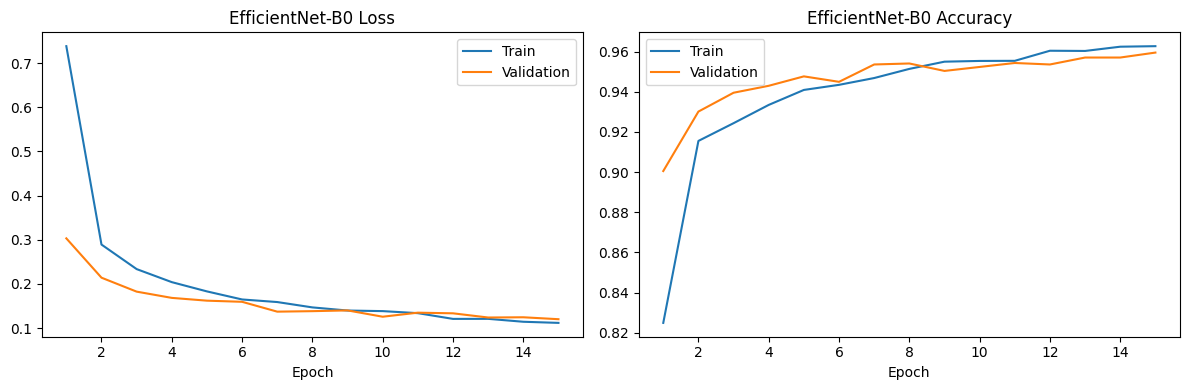

In [27]:
EFF_NUM_EPOCHS = 15
EFF_PATIENCE = 4
efficientnet_best_val_loss = float("inf")
efficientnet_best_epoch = 0
efficientnet_best_state = None
efficientnet_wait = 0
efficientnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

efficientnet_training_start = time.perf_counter()
for epoch in range(1, EFF_NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss, train_accuracy = run_model_epoch(
        efficientnet_model, train_loader, eff_criterion, eff_optimizer
    )
    val_loss, val_accuracy = run_model_epoch(
        efficientnet_model, val_loader, eff_criterion
    )

    efficientnet_history["train_loss"].append(train_loss)
    efficientnet_history["val_loss"].append(val_loss)
    efficientnet_history["train_accuracy"].append(train_accuracy)
    efficientnet_history["val_accuracy"].append(val_accuracy)

    if val_loss < efficientnet_best_val_loss:
        efficientnet_best_val_loss = val_loss
        efficientnet_best_epoch = epoch
        efficientnet_best_state = copy.deepcopy(efficientnet_model.state_dict())
        efficientnet_wait = 0
    else:
        efficientnet_wait += 1

    print(
        f"Epoch {epoch:02d}/{EFF_NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{time.perf_counter() - epoch_start:.1f}s"
    )
    if efficientnet_wait >= EFF_PATIENCE:
        print(f"Early stopping: validation loss did not improve for {EFF_PATIENCE} epochs.")
        break

efficientnet_training_seconds = time.perf_counter() - efficientnet_training_start
if efficientnet_best_state is None:
    raise RuntimeError("EfficientNet training did not produce a best validation checkpoint.")
efficientnet_model.load_state_dict(efficientnet_best_state)
print(
    f"Best epoch: {efficientnet_best_epoch} | "
    f"best validation loss: {efficientnet_best_val_loss:.4f} | "
    f"training time: {efficientnet_training_seconds:.1f}s"
)

eff_epochs = range(1, len(efficientnet_history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(eff_epochs, efficientnet_history["train_loss"], label="Train")
axes[0].plot(eff_epochs, efficientnet_history["val_loss"], label="Validation")
axes[0].set(title="EfficientNet-B0 Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(eff_epochs, efficientnet_history["train_accuracy"], label="Train")
axes[1].plot(eff_epochs, efficientnet_history["val_accuracy"], label="Validation")
axes[1].set(title="EfficientNet-B0 Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 28. Save the Best EfficientNet-B0 Checkpoint

Save the validation-selected weights and the preprocessing/class metadata. The checkpoint is written only after the training cell has completed.

In [28]:
if efficientnet_best_state is None:
    raise RuntimeError("Run the EfficientNet training cell before saving its checkpoint.")

EFFICIENTNET_MODEL_PATH = Path("best_efficientnet_b0_eurosat.pth")
efficientnet_model.load_state_dict(efficientnet_best_state)
efficientnet_checkpoint = {
    "model_state_dict": {
        key: value.detach().cpu() for key, value in efficientnet_model.state_dict().items()
    },
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
    "best_epoch": efficientnet_best_epoch,
    "best_validation_loss": efficientnet_best_val_loss,
}
torch.save(efficientnet_checkpoint, EFFICIENTNET_MODEL_PATH)
print("Saved EfficientNet-B0 checkpoint:", EFFICIENTNET_MODEL_PATH.resolve())
print(f"Checkpoint size: {EFFICIENTNET_MODEL_PATH.stat().st_size / (1024 ** 2):.2f} MiB")

Saved EfficientNet-B0 checkpoint: /content/best_efficientnet_b0_eurosat.pth
Checkpoint size: 15.61 MiB


## 29. EfficientNet-B0 Final Test Evaluation

Evaluate the validation-selected EfficientNet model on the held-out test loader. This is the final test evaluation for EfficientNet; do not use these results to tune it.

In [29]:
if efficientnet_best_state is None:
    raise RuntimeError("Run EfficientNet training before test evaluation.")
efficientnet_model.load_state_dict(efficientnet_best_state)
efficientnet_model.eval()

efficientnet_test_labels = []
efficientnet_test_predictions = []
efficientnet_test_probabilities = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = efficientnet_model(images)
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
        efficientnet_test_probabilities.extend(probabilities)
        efficientnet_test_predictions.extend(probabilities.argmax(axis=1))
        efficientnet_test_labels.extend(labels.numpy())

efficientnet_test_probabilities = np.asarray(efficientnet_test_probabilities)
efficientnet_test_accuracy = accuracy_score(
    efficientnet_test_labels, efficientnet_test_predictions
)
print(f"EfficientNet-B0 test accuracy: {efficientnet_test_accuracy:.4f}")
print("Test images:", len(efficientnet_test_labels))

EfficientNet-B0 test accuracy: 0.9605
Test images: 4050


## 30. EfficientNet Confusion Matrix and Classification Report

Inspect class-by-class test performance and the most frequent error patterns for EfficientNet-B0.

                      precision    recall  f1-score   support

          AnnualCrop     0.9903    0.9067    0.9466       450
              Forest     0.9634    0.9956    0.9792       450
HerbaceousVegetation     0.9573    0.9467    0.9520       450
             Highway     0.9539    0.9387    0.9462       375
          Industrial     0.9840    0.9867    0.9854       375
             Pasture     0.9117    0.9633    0.9368       300
       PermanentCrop     0.9100    0.9440    0.9267       375
         Residential     0.9739    0.9956    0.9846       450
               River     0.9475    0.9627    0.9550       375
             SeaLake     0.9954    0.9644    0.9797       450

            accuracy                         0.9605      4050
           macro avg     0.9588    0.9604    0.9592      4050
        weighted avg     0.9612    0.9605    0.9605      4050



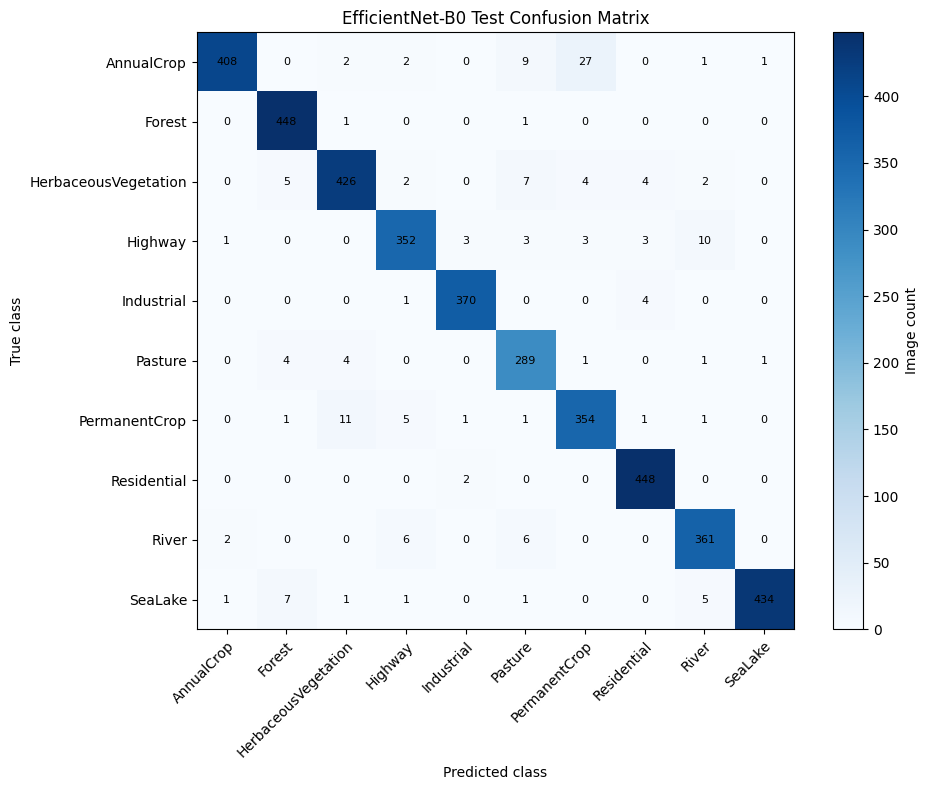

In [30]:
efficientnet_confusion = confusion_matrix(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
)
efficientnet_report_dict = classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    digits=4,
    zero_division=0,
)
print(classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(efficientnet_confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EfficientNet-B0 Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(efficientnet_confusion[row, column]),
                ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 31. ResNet50 vs EfficientNet-B0 Comparison

Compare both models on the same held-out test set. The ResNet50 time is explicitly labeled approximate because the original notebook saved per-epoch times rounded to 0.1 seconds; EfficientNet time is measured with a timer. Checkpoint sizes are read from the saved files.

,Model,Test accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Checkpoint size (MiB)
0,ResNet50,0.9820,0.9811,0.9817,0.9814,103.3000,90.0526
1,EfficientNet-B0,0.9605,0.9588,0.9604,0.9592,147.6946,15.6094


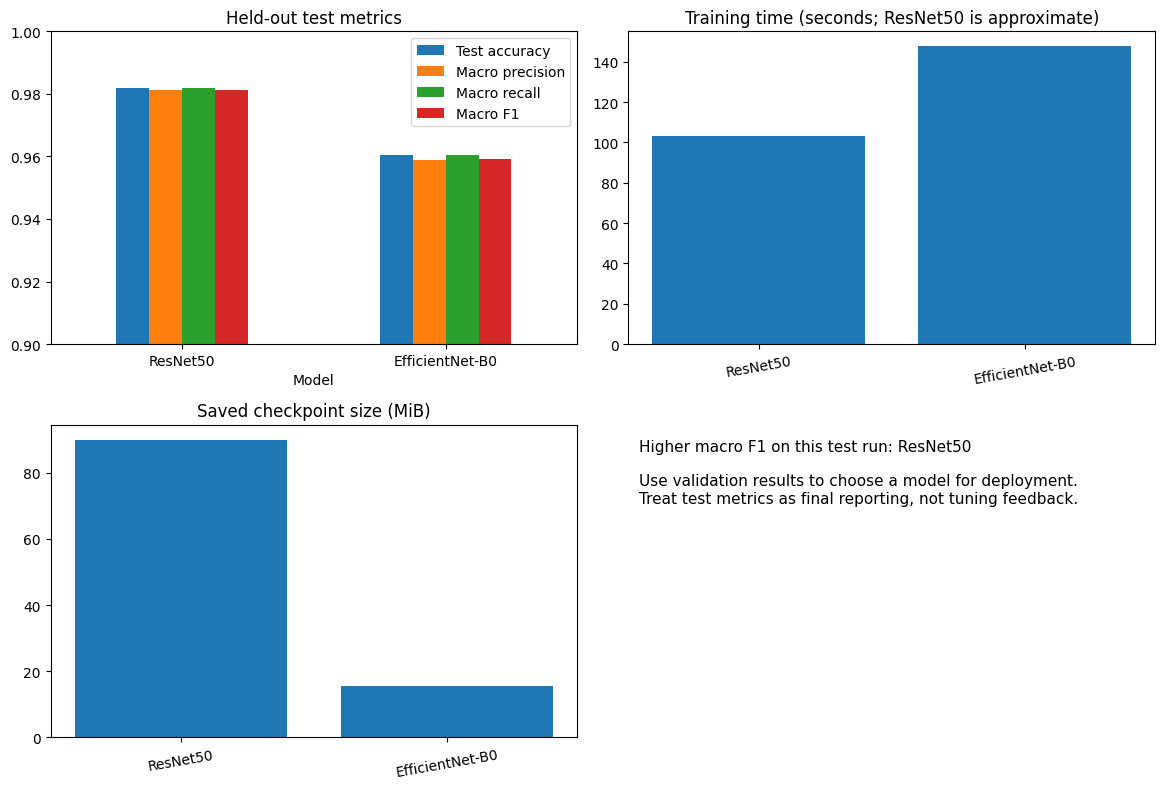

In [31]:
if not Path(MODEL_PATH).exists():
    raise FileNotFoundError("Run the ResNet50 model-saving cell before this comparison.")
if not Path(EFFICIENTNET_MODEL_PATH).exists():
    raise FileNotFoundError("Run the EfficientNet training and checkpoint cells first.")

efficientnet_report_for_comparison = classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
model_comparison = pd.DataFrame([
    {
        "Model": "ResNet50",
        "Test accuracy": accuracy_score(all_labels, all_predictions),
        "Macro precision": baseline_report_dict["macro avg"]["precision"],
        "Macro recall": baseline_report_dict["macro avg"]["recall"],
        "Macro F1": baseline_report_dict["macro avg"]["f1-score"],
        "Training time (s)": baseline_training_seconds_approx,
        "Checkpoint size (MiB)": Path(MODEL_PATH).stat().st_size / (1024 ** 2),
    },
    {
        "Model": "EfficientNet-B0",
        "Test accuracy": efficientnet_test_accuracy,
        "Macro precision": efficientnet_report_for_comparison["macro avg"]["precision"],
        "Macro recall": efficientnet_report_for_comparison["macro avg"]["recall"],
        "Macro F1": efficientnet_report_for_comparison["macro avg"]["f1-score"],
        "Training time (s)": efficientnet_training_seconds,
        "Checkpoint size (MiB)": EFFICIENTNET_MODEL_PATH.stat().st_size / (1024 ** 2),
    },
])
display(model_comparison.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metric_columns = ["Test accuracy", "Macro precision", "Macro recall", "Macro F1"]
model_comparison.set_index("Model")[metric_columns].plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Held-out test metrics")
axes[0, 0].set_ylim(0.90, 1.0)
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 1].bar(model_comparison["Model"], model_comparison["Training time (s)"])
axes[0, 1].set_title("Training time (seconds; ResNet50 is approximate)")
axes[0, 1].tick_params(axis="x", rotation=10)
axes[1, 0].bar(model_comparison["Model"], model_comparison["Checkpoint size (MiB)"])
axes[1, 0].set_title("Saved checkpoint size (MiB)")
axes[1, 0].tick_params(axis="x", rotation=10)
axes[1, 1].axis("off")
f1_winner = model_comparison.loc[model_comparison["Macro F1"].idxmax(), "Model"]
axes[1, 1].text(
    0.02, 0.75,
    f"Higher macro F1 on this test run: {f1_winner}\n\n"
    "Use validation results to choose a model for deployment.\n"
    "Treat test metrics as final reporting, not tuning feedback.",
    fontsize=11,
)
plt.tight_layout()
plt.show()

## 32. Per-Class Performance and Most Confused Classes

Compare per-class precision, recall, and F1, then list the largest off-diagonal errors. These tables explain which land-cover classes are hardest for each model.

In [32]:
baseline_confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
baseline_report_for_comparison = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

per_class_comparison = pd.DataFrame({
    "Class": class_names,
    "ResNet50 precision": [baseline_report_for_comparison[name]["precision"] for name in class_names],
    "ResNet50 recall": [baseline_report_for_comparison[name]["recall"] for name in class_names],
    "ResNet50 F1": [baseline_report_for_comparison[name]["f1-score"] for name in class_names],
    "EfficientNet precision": [efficientnet_report_for_comparison[name]["precision"] for name in class_names],
    "EfficientNet recall": [efficientnet_report_for_comparison[name]["recall"] for name in class_names],
    "EfficientNet F1": [efficientnet_report_for_comparison[name]["f1-score"] for name in class_names],
})
display(per_class_comparison.round(4))

def top_confusion_pairs(matrix, labels, top_n=5):
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pairs = []
    for true_index, predicted_index in zip(*np.where(off_diagonal > 0)):
        pairs.append({
            "True class": labels[true_index],
            "Predicted as": labels[predicted_index],
            "Count": int(off_diagonal[true_index, predicted_index]),
        })
    if not pairs:
        return pd.DataFrame(columns=["True class", "Predicted as", "Count"])
    return pd.DataFrame(pairs).sort_values("Count", ascending=False).head(top_n)

print("ResNet50: most frequent confusion pairs")
display(top_confusion_pairs(baseline_confusion, class_names))
print("EfficientNet-B0: most frequent confusion pairs")
display(top_confusion_pairs(efficientnet_confusion, class_names))

,Class,ResNet50 precision,ResNet50 recall,ResNet50 F1,EfficientNet precision,EfficientNet recall,EfficientNet F1
0,AnnualCrop,0.9797,0.9644,0.9720,0.9903,0.9067,0.9466
1,Forest,0.9933,0.9956,0.9945,0.9634,0.9956,0.9792
2,HerbaceousVegetation,0.9647,0.9711,0.9679,0.9573,0.9467,0.9520
3,Highway,0.9789,0.9920,0.9854,0.9539,0.9387,0.9462
4,Industrial,0.9947,0.9947,0.9947,0.9840,0.9867,0.9854
5,Pasture,0.9577,0.9800,0.9687,0.9117,0.9633,0.9368
6,PermanentCrop,0.9649,0.9520,0.9584,0.9100,0.9440,0.9267
7,Residential,0.9956,0.9978,0.9967,0.9739,0.9956,0.9846
8,River,0.9839,0.9787,0.9813,0.9475,0.9627,0.9550
9,SeaLake,0.9978,0.9911,0.9944,0.9954,0.9644,0.9797


ResNet50: most frequent confusion pairs


,True class,Predicted as,Count
20,PermanentCrop,HerbaceousVegetation,10
2,AnnualCrop,Pasture,8
9,HerbaceousVegetation,PermanentCrop,6
3,AnnualCrop,PermanentCrop,6
19,PermanentCrop,AnnualCrop,5


EfficientNet-B0: most frequent confusion pairs


,True class,Predicted as,Count
3,AnnualCrop,PermanentCrop,27
28,PermanentCrop,HerbaceousVegetation,11
19,Highway,River,10
2,AnnualCrop,Pasture,9
10,HerbaceousVegetation,Pasture,7


## 33. Correct and Incorrect Prediction Examples with Confidence

Visualize representative ResNet50 predictions from the held-out test set. Confidence is the model's softmax score for its predicted class; it is not a guarantee that the prediction is correct.

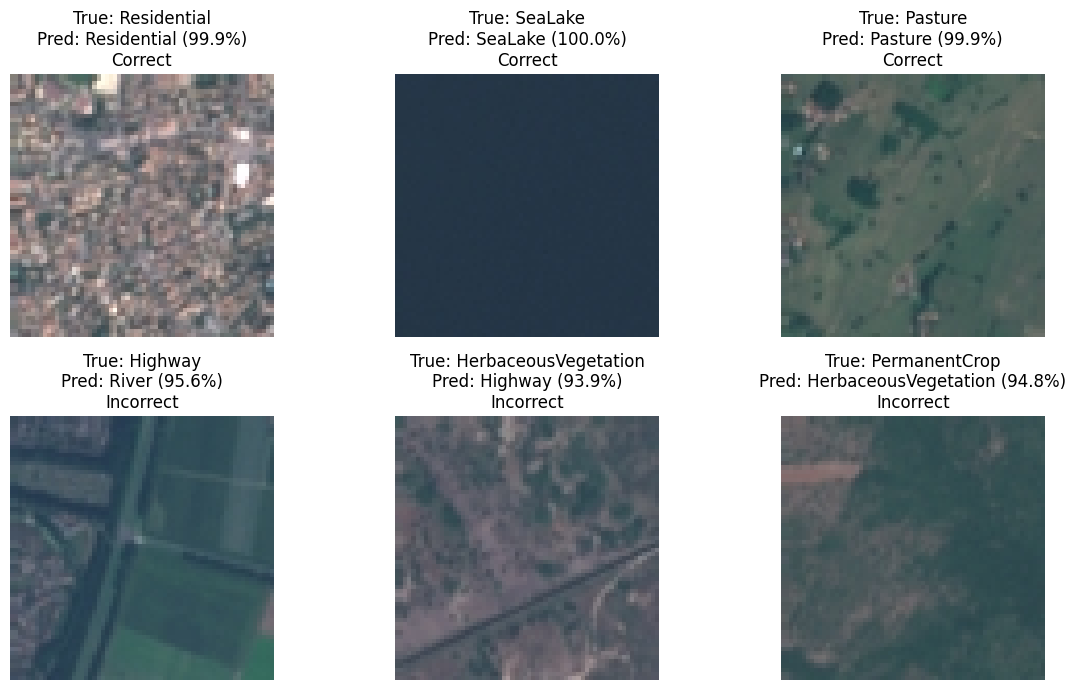

In [33]:
baseline_true_array = np.asarray(all_labels)
baseline_pred_array = np.asarray(all_predictions)
correct_positions = np.flatnonzero(baseline_true_array == baseline_pred_array)[:3]
incorrect_positions = np.flatnonzero(baseline_true_array != baseline_pred_array)[:3]
example_positions = list(correct_positions) + list(incorrect_positions)
if len(incorrect_positions) == 0:
    print("No incorrect test predictions are available to display.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    axes = axes.ravel()
    for axis, test_position in zip(axes, example_positions):
        normalized_tensor, true_label = test_set[int(test_position)]
        original_dataset_index = test_set.indices[int(test_position)]
        original_image, _ = dataset[original_dataset_index]
        input_tensor = normalized_tensor.unsqueeze(0).to(device)
        with torch.no_grad():
            probabilities = torch.softmax(loaded_model(input_tensor), dim=1)[0]
        predicted_index = int(probabilities.argmax().item())
        confidence = float(probabilities[predicted_index].item())
        is_correct = predicted_index == int(true_label)
        axis.imshow(original_image)
        axis.set_title(
            f"True: {class_names[int(true_label)]}\n"
            f"Pred: {class_names[predicted_index]} ({confidence:.1%})\n"
            f"{'Correct' if is_correct else 'Incorrect'}"
        )
        axis.axis("off")
    for axis in axes[len(example_positions):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## 34. Explainability with Grad-CAM

Grad-CAM uses gradients flowing into a final convolutional layer to create a coarse heatmap of image regions that support a chosen class score. The implementation below explains ResNet50 predictions, including one correct and one incorrect test example. Heatmaps are diagnostic visualizations, not proof of causal reasoning. [Original Grad-CAM paper](https://arxiv.org/abs/1610.02391).

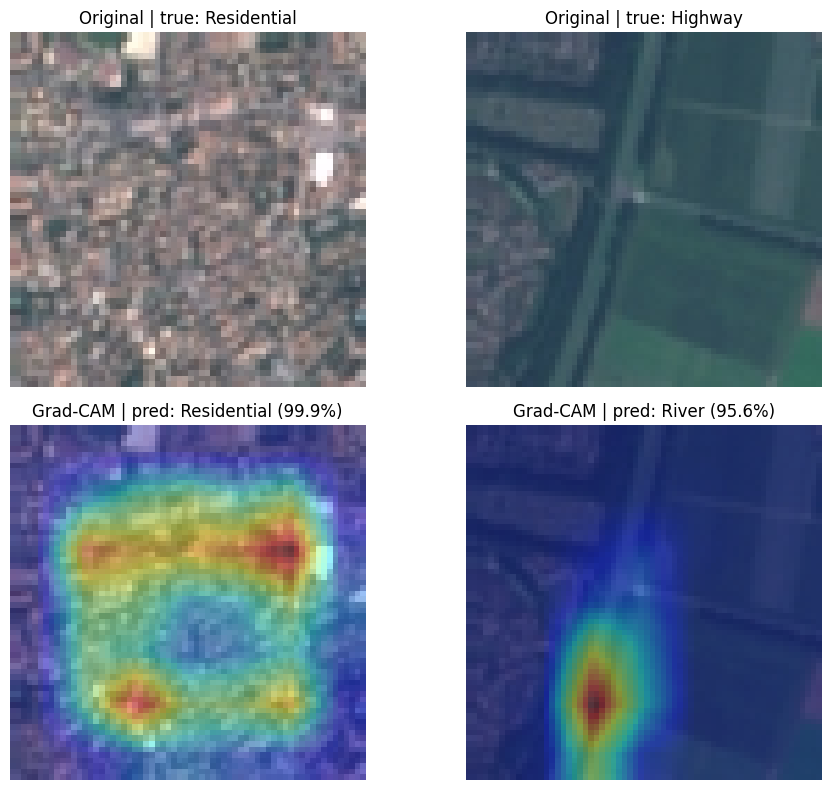

In [34]:
import torch.nn.functional as F

def generate_gradcam(model_to_explain, target_layer, image_tensor, output_size):
    activations = {}
    gradients = {}

    def capture_activation(module, inputs, output):
        activations["feature"] = output
        output.register_hook(lambda gradient: gradients.__setitem__("feature", gradient.detach()))

    hook_handle = target_layer.register_forward_hook(capture_activation)
    model_to_explain.eval()
    model_to_explain.zero_grad(set_to_none=True)
    input_batch = image_tensor.unsqueeze(0).to(device)
    logits = model_to_explain(input_batch)
    predicted_index = int(logits.argmax(dim=1).item())
    score = logits[:, predicted_index].sum()
    score.backward()
    hook_handle.remove()

    feature_maps = activations["feature"].detach()
    feature_gradients = gradients["feature"]
    channel_weights = feature_gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((channel_weights * feature_maps).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=output_size, mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / cam.max().clamp_min(1e-8)
    confidence = torch.softmax(logits.detach(), dim=1)[0, predicted_index].item()
    return predicted_index, confidence, cam.cpu().numpy()

if len(correct_positions) == 0 or len(incorrect_positions) == 0:
    raise RuntimeError("Grad-CAM examples require at least one correct and one incorrect test prediction.")

gradcam_positions = [int(correct_positions[0]), int(incorrect_positions[0])]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for column, test_position in enumerate(gradcam_positions):
    normalized_tensor, true_label = test_set[test_position]
    original_dataset_index = test_set.indices[test_position]
    original_image, _ = dataset[original_dataset_index]
    heatmap_size = (original_image.height, original_image.width)
    predicted_index, confidence, heatmap = generate_gradcam(
        loaded_model, loaded_model.layer4, normalized_tensor, heatmap_size
    )
    axes[0, column].imshow(original_image)
    axes[0, column].set_title(f"Original | true: {class_names[int(true_label)]}")
    axes[1, column].imshow(original_image)
    axes[1, column].imshow(heatmap, cmap="jet", alpha=0.40)
    axes[1, column].set_title(
        f"Grad-CAM | pred: {class_names[predicted_index]} ({confidence:.1%})"
    )
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.show()

## 35. Multispectral EuroSAT: Separate Extension Plan

The current model uses three RGB channels. The original EuroSAT release also provides EuroSAT_MS.zip with all 13 Sentinel-2 bands in their original value range; these must be treated as a separate dataset and preprocessing pipeline. Sentinel-2 bands have native 10 m, 20 m, or 60 m resolutions, so alignment and per-band scaling must be checked before training. Sources: [EuroSAT paper](https://arxiv.org/abs/1709.00029), [EuroSAT Zenodo record](https://zenodo.org/records/7711097), and [Sentinel-2 product specification](https://sentinels.copernicus.eu/documents/d/sentinel/sentinel-2-products-specification-document-15_1).

In [35]:
multispectral_comparison = pd.DataFrame([
    {"Input": "RGB EuroSAT", "Channels": 3, "Typical tensor": "[B, 3, 64, 64] before resize", "Preprocessing": "RGB conversion, ImageNet normalization"},
    {"Input": "EuroSAT multispectral", "Channels": 13, "Typical tensor": "[B, 13, 64, 64]", "Preprocessing": "Align bands; inspect original range; normalize each band using training data only"},
])
display(multispectral_comparison)

sentinel_band_groups = pd.DataFrame([
    {"Native resolution": "10 m", "Sentinel-2 bands": "B2, B3, B4, B8"},
    {"Native resolution": "20 m", "Sentinel-2 bands": "B5, B6, B7, B8A, B11, B12"},
    {"Native resolution": "60 m", "Sentinel-2 bands": "B1, B9, B10"},
])
display(sentinel_band_groups)

def adapt_resnet50_first_layer_to_13_bands(num_classes=NUM_CLASSES, num_bands=13):
    """Create a separate 13-channel ResNet50; this does not modify either RGB model."""
    multispectral_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    old_conv = multispectral_model.conv1
    new_conv = nn.Conv2d(
        in_channels=num_bands,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )
    with torch.no_grad():
        mean_rgb_kernel = old_conv.weight.mean(dim=1, keepdim=True)
        new_conv.weight.copy_(mean_rgb_kernel.repeat(1, num_bands, 1, 1) * (3 / num_bands))
    multispectral_model.conv1 = new_conv
    multispectral_model.fc = nn.Linear(multispectral_model.fc.in_features, num_classes)
    return multispectral_model

print("The 13-band model factory is defined but not called; no multispectral data is mixed into RGB training.")

,Input,Channels,Typical tensor,Preprocessing
0,RGB EuroSAT,3,"[B, 3, 64, 64] before resize","RGB conversion, ImageNet normalization"
1,EuroSAT multispectral,13,"[B, 13, 64, 64]",Align bands; inspect original range; normalize...


,Native resolution,Sentinel-2 bands
0,10 m,"B2, B3, B4, B8"
1,20 m,"B5, B6, B7, B8A, B11, B12"
2,60 m,"B1, B9, B10"


The 13-band model factory is defined but not called; no multispectral data is mixed into RGB training.


## 36. Practical Optimization Options

The existing pipelines already use transfer learning, early stopping, and best-checkpoint selection. For a new controlled experiment, reduce the learning rate when validation loss plateaus; apply the same policy to both architectures if comparing them. Tune only on the validation set, never on test results.

In [36]:
def make_validation_lr_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
    )

# Optional for a future training run:
# scheduler = make_validation_lr_scheduler(optimizer)
# After each validation epoch, call: scheduler.step(val_loss)
# Keep this experiment separate from the already-reported baseline results.

optimization_experiments = pd.DataFrame([
    {"Experiment": "Learning-rate schedule", "Selection data": "Validation", "Purpose": "Reduce learning rate after a validation-loss plateau"},
    {"Experiment": "Unfreeze more/less layers", "Selection data": "Validation", "Purpose": "Trade adaptation capacity against compute and overfitting"},
    {"Experiment": "Batch size / learning rate", "Selection data": "Validation", "Purpose": "Measure stability and GPU memory use"},
])
display(optimization_experiments)

,Experiment,Selection data,Purpose
0,Learning-rate schedule,Validation,Reduce learning rate after a validation-loss p...
1,Unfreeze more/less layers,Validation,Trade adaptation capacity against compute and ...
2,Batch size / learning rate,Validation,Measure stability and GPU memory use


## 37. Inference Speed Measurement

Measure single-image inference after warm-up for both trained models on the same device. This is a runtime benchmark, not a change to model weights or test-set metrics.

In [37]:
def benchmark_single_image(model_to_benchmark, image_tensor, warmup=10, iterations=50):
    model_to_benchmark.eval()
    input_batch = image_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model_to_benchmark(input_batch)
        if device.type == "cuda":
            torch.cuda.synchronize()
        start_time = time.perf_counter()
        for _ in range(iterations):
            _ = model_to_benchmark(input_batch)
        if device.type == "cuda":
            torch.cuda.synchronize()
    average_ms = (time.perf_counter() - start_time) * 1000 / iterations
    return average_ms

benchmark_image, _ = test_set[0]
speed_results = pd.DataFrame([
    {"Model": "ResNet50", "Average single-image latency (ms)": benchmark_single_image(loaded_model, benchmark_image)},
    {"Model": "EfficientNet-B0", "Average single-image latency (ms)": benchmark_single_image(efficientnet_model, benchmark_image)},
])
speed_results["Images per second (approx.)"] = 1000 / speed_results["Average single-image latency (ms)"]
display(speed_results.round(2))

,Model,Average single-image latency (ms),Images per second (approx.)
0,ResNet50,1.57,637.04
1,EfficientNet-B0,2.01,498.47


## 38. Optional Gradio App Preparation

This separate cell prepares an upload interface with an image preview, predicted class/confidence, and top-three classes. Select the deployment model after reviewing validation results. The cell only launches the interface when you run it manually. [Gradio Image component documentation](https://www.gradio.app/docs/gradio/image).

In [38]:
try:
    import gradio as gr
except ImportError as error:
    raise ImportError("Install Gradio in Colab with pip install gradio, then rerun this cell.") from error

DEPLOY_MODEL_NAME = "ResNet50"  # Set to "EfficientNet-B0" after reviewing validation performance.
if DEPLOY_MODEL_NAME == "ResNet50":
    deployment_model = loaded_model
elif DEPLOY_MODEL_NAME == "EfficientNet-B0":
    deployment_model = efficientnet_model
else:
    raise ValueError("DEPLOY_MODEL_NAME must be 'ResNet50' or 'EfficientNet-B0'.")
deployment_model.eval()

def predict_for_gradio(pil_image):
    if pil_image is None:
        return None, "Upload an RGB satellite image.", {}
    pil_image = pil_image.convert("RGB")
    image_tensor = eval_transform(pil_image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(deployment_model(image_tensor), dim=1)[0]
    top_probabilities, top_indices = probabilities.topk(3)
    predicted_index = int(top_indices[0].item())
    prediction_text = (
        f"Prediction: {class_names[predicted_index]} "
        f"({top_probabilities[0].item():.1%} model score)"
    )
    top_three = {
        class_names[int(index.item())]: float(probability.item())
        for index, probability in zip(top_indices, top_probabilities)
    }
    return pil_image, prediction_text, top_three

with gr.Blocks(title="EuroSAT Land Cover Classifier") as demo:
    gr.Markdown("# EuroSAT Land Cover Classifier\nUpload an RGB satellite image to see the predicted class and top three scores.")
    with gr.Row():
        image_input = gr.Image(type="pil", label="Upload satellite image")
        image_preview = gr.Image(label="Image preview")
    prediction_output = gr.Textbox(label="Prediction")
    top_three_output = gr.Label(label="Top 3 classes", num_top_classes=3)
    predict_button = gr.Button("Classify image")
    predict_button.click(
        predict_for_gradio,
        inputs=image_input,
        outputs=[image_preview, prediction_output, top_three_output],
    )

# Run manually to start the local Colab interface; sharing is disabled by default.
demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 39. Final Project Documentation

### Problem and objectives
Land-cover classification assigns a satellite image to one of ten EuroSAT categories. This project builds a reproducible RGB baseline and compares it with a second transfer-learning architecture.

### Dataset and methodology
The RGB experiment uses EuroSAT's 27,000 64 × 64 images, a stratified 70/15/15 split, training-only augmentation, 224 × 224 inputs, and ImageNet normalization. The baseline uses pretrained ResNet50; the extension uses pretrained EfficientNet-B0. Each model selects weights using validation loss and reports final metrics on the held-out test set.

### Experimental results
The attached completed notebook reports **ResNet50 test accuracy = 98.20%**, macro precision = 98.11%, macro recall = 98.17%, and macro F1 = 98.14% across 4,050 test images. Its best validation epoch was 6. The recorded epoch durations sum to approximately 103.3 seconds (the displayed per-epoch values were rounded). EfficientNet-B0 results remain pending until its training/evaluation cells are run; the comparison table intentionally computes them from actual outputs.

### Explainability and multispectral scope
Grad-CAM highlights coarse regions associated with a class score; it helps inspect model behavior but does not prove causal reasoning. The current RGB weights accept three channels only. EuroSAT_MS is a separate 13-band dataset and needs its own aligned data pipeline, band-specific normalization, and a 13-channel first layer.

### Limitations and future work
The random image split is not a geographic holdout, so spatially related scenes could make generalization appear stronger than performance in a new region. Softmax scores are not calibrated probabilities. Metrics apply to this dataset and split; future work can compare models across geographic regions, test the multispectral dataset separately, calibrate confidence, and evaluate deployment latency on target hardware.

### References
- [EuroSAT paper](https://arxiv.org/abs/1709.00029)
- [EuroSAT RGB and multispectral files on Zenodo](https://zenodo.org/records/7711097)
- [Sentinel-2 MSI band-resolution specification](https://sentinels.copernicus.eu/documents/d/sentinel/sentinel-2-products-specification-document-15_1)
- [Torchvision EfficientNet-B0 documentation](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html)
- [Grad-CAM paper](https://arxiv.org/abs/1610.02391)
- [Gradio Image documentation](https://www.gradio.app/docs/gradio/image)


In [39]:
final_status = {
    "ResNet50 test accuracy": float(accuracy_score(all_labels, all_predictions)),
    "ResNet50 macro F1": float(baseline_report_dict["macro avg"]["f1-score"]),
    "EfficientNet trained": "efficientnet_test_accuracy" in globals(),
}
if final_status["EfficientNet trained"]:
    final_status["EfficientNet-B0 test accuracy"] = float(efficientnet_test_accuracy)
    final_status["EfficientNet-B0 macro F1"] = float(efficientnet_report_dict["macro avg"]["f1-score"])
else:
    final_status["EfficientNet-B0 test accuracy"] = "Run EfficientNet training and evaluation to populate."
display(pd.DataFrame([final_status]))

,ResNet50 test accuracy,ResNet50 macro F1,EfficientNet trained,EfficientNet-B0 test accuracy,EfficientNet-B0 macro F1
0,0.981975,0.98139,True,0.960494,0.959223


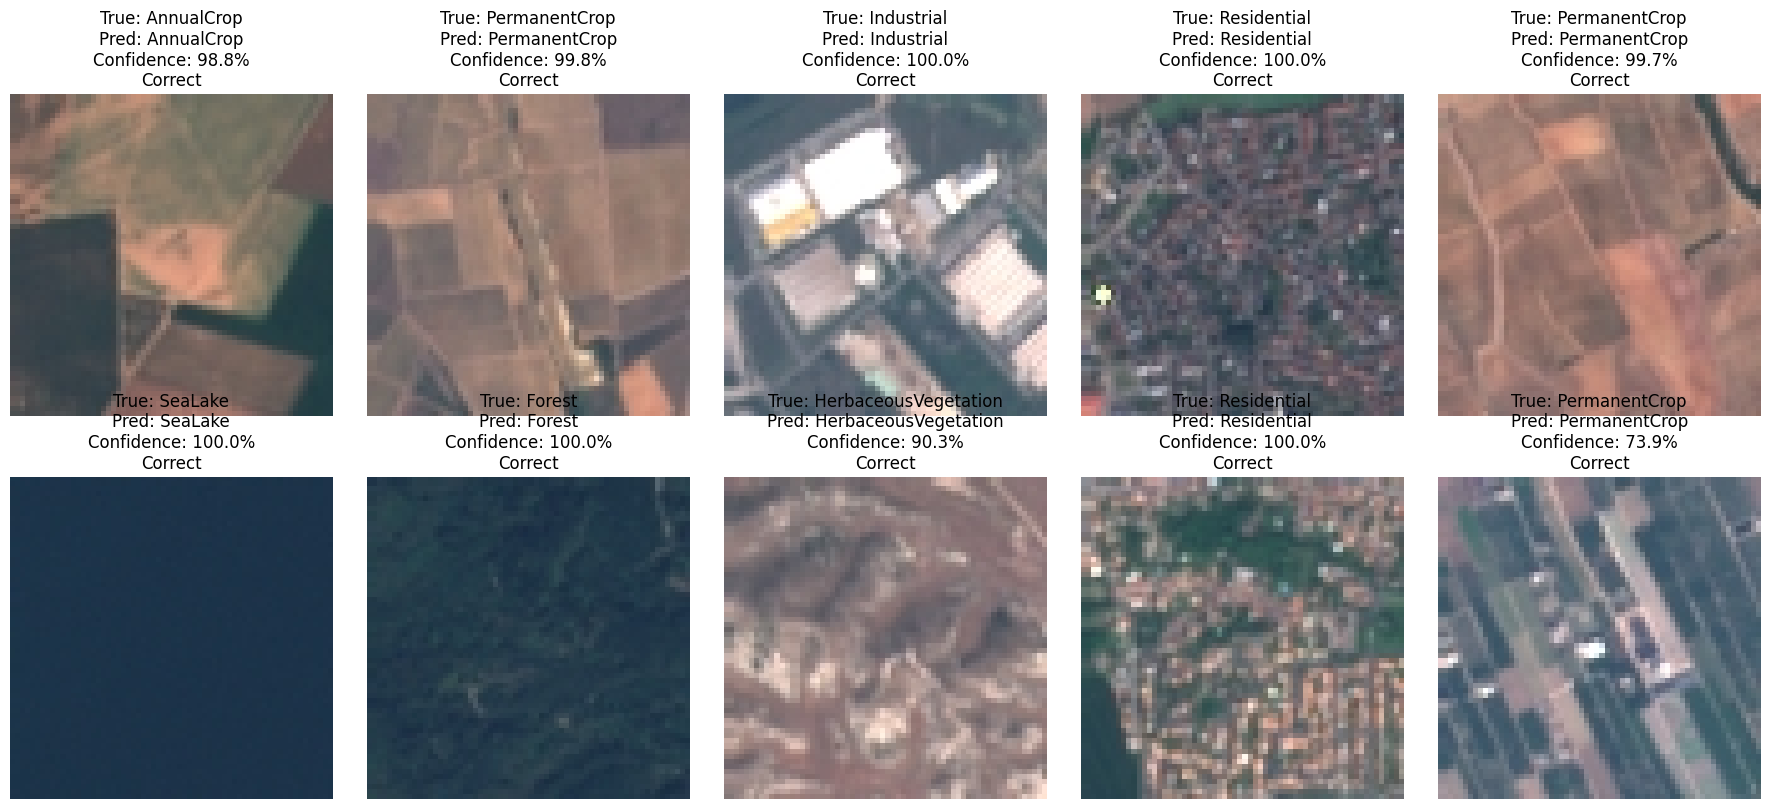

Correct Predictions: 10/10
Sample Accuracy: 100%


In [40]:
import random
import matplotlib.pyplot as plt
import torch

# Select 10 random images from the test dataset
random.seed(42)
sample_indices = random.sample(range(len(test_set)), 10)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

correct = 0

for ax, idx in zip(axes, sample_indices):

    image_tensor, true_label = test_set[idx]

    # Get original image
    original_idx = test_set.indices[idx]
    original_image, _ = dataset[original_idx]

    # Predict
    image_batch = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = loaded_model(image_batch)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_label = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

    is_correct = predicted_label == true_label

    if is_correct:
        correct += 1

    ax.imshow(original_image)

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1%}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Correct Predictions: {correct}/10")
print(f"Sample Accuracy: {correct * 10}%")

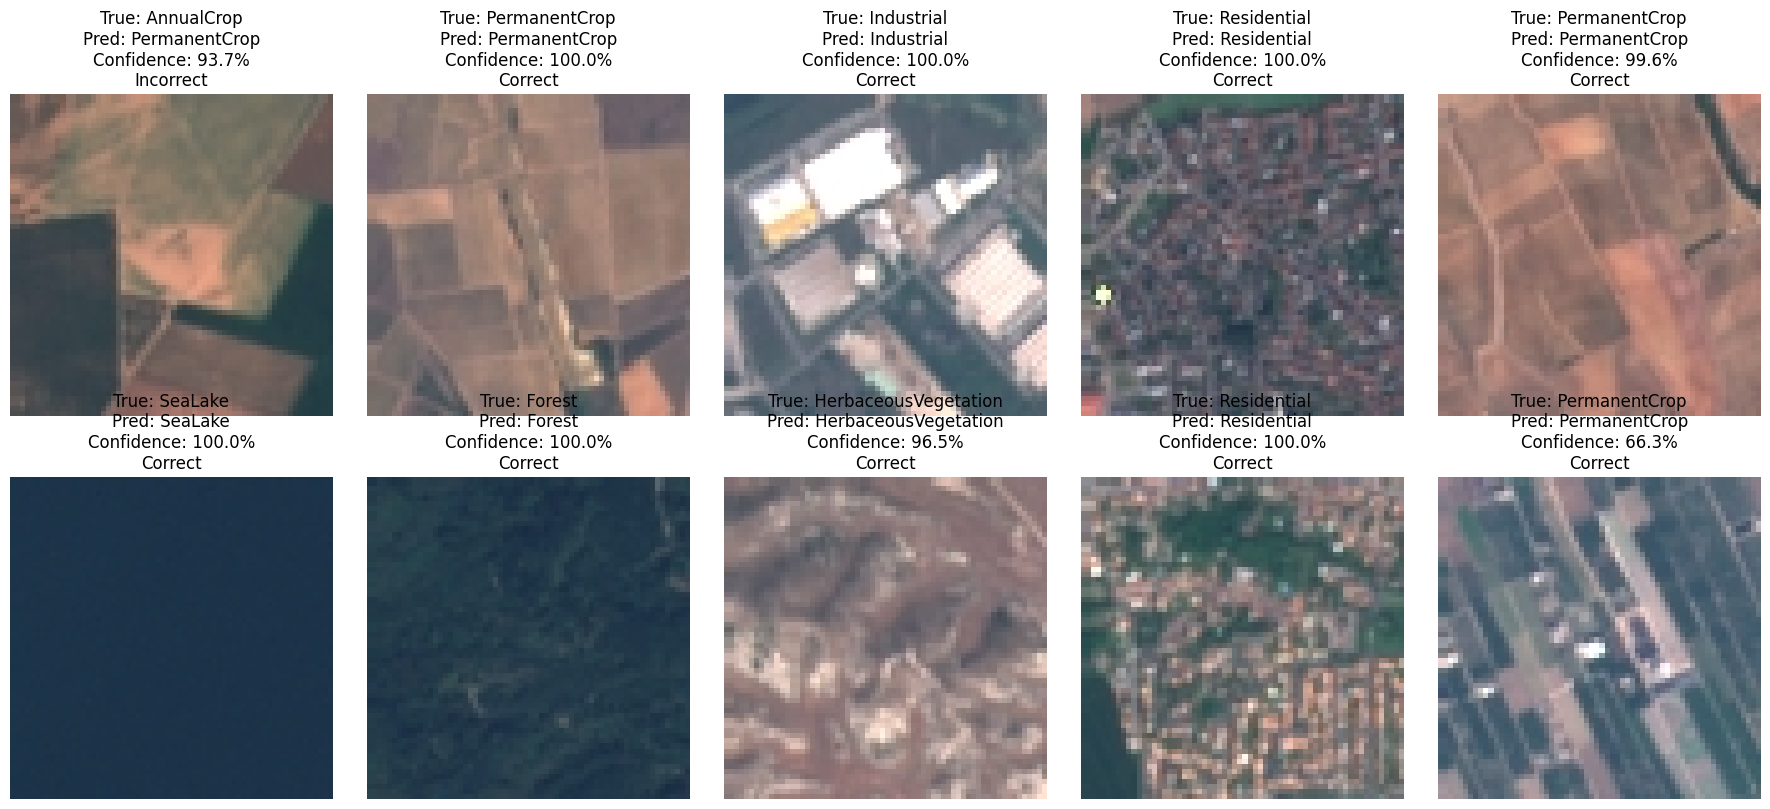

EfficientNet Correct: 9/10
EfficientNet Sample Accuracy: 90%


In [41]:
# Test EfficientNet-B0 on the same 10 images

efficientnet_model.eval()

correct = 0

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):

    image_tensor, true_label = test_set[idx]

    original_idx = test_set.indices[idx]
    original_image, _ = dataset[original_idx]

    image_batch = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = efficientnet_model(image_batch)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_label = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

    is_correct = predicted_label == true_label

    if is_correct:
        correct += 1

    ax.imshow(original_image)

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1%}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"EfficientNet Correct: {correct}/10")
print(f"EfficientNet Sample Accuracy: {correct * 10}%")